In [2]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans, AgglomerativeClustering

In [3]:
from matplotlib.image import imread
from IPython.display import Image as ImageDisplay

# read the files and convert to numpy arrays by pixel
image_map = imread(r'./assets/image/jupyter-logo.png')
print('Height: {}, Weight: {} in pixels descomposed in tuple {} (red, green, blue, alpha)'.format(*image_map.shape))

Height: 630, Weight: 1200 in pixels descomposed in tuple 4 (red, green, blue, alpha)


In [21]:
# we join the pixels in a single array
map_array = image_map.reshape(image_map.shape[0]*image_map.shape[1], 4)

In [34]:
kmeans = KMeans()
kmeans.fit(map_array)

KMeans()

In [35]:
kmeans_labels = kmeans.predict(map_array)

In [36]:
classes, counts = np.unique(kmeans_labels, return_counts=True)
counts_normalize = counts/counts.sum()

In [37]:
import matplotlib.patches as patches

def color_swatches(colors):

    ncolors = len(colors)
    fig, ax = plt.subplots(figsize=(ncolors*2, 2))

    for (start_x, color) in enumerate(colors):
        color_rect = patches.Rectangle((start_x, 0), 1, 1, color=color)
        ax.add_patch(color_rect)

    ax.set_xlim(0, len(colors))
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_yticklabels([])
    ax.set_xticks([])
    ax.set_xticklabels([])

    return fig

Perecentage of composition:  [89.07  6.47  0.85  0.9   0.21  2.12  0.21  0.17]


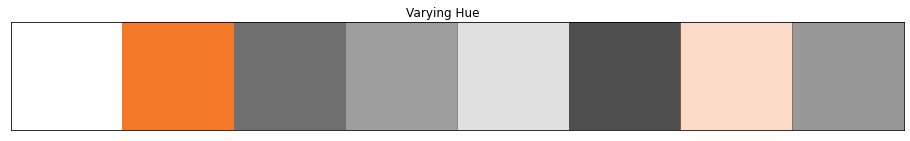

In [43]:
colors = list(np.abs(kmeans.cluster_centers_)) #/kmeans.cluster_centers_.max())
fig = color_swatches(colors)
fig.suptitle("Varying Hue")
print("Perecentage of composition: ",counts_normalize.round(4)*100)

In [19]:
with Image.open('./assets/image/jupyter-logo.png') as img:
    to_crop = (280, 0, img.width - 280, img.height)
    img = img.crop(to_crop)
    # new_size = (img.size[0]*0.2, img.size[1]*0.2)
    # img.thumbnail(new_size)
    img.save('./assets/image/jupyter-logo-thumbnail.png')
    # print(img.size)

In [9]:
img.mode

'RGBA'

In [2]:
with open('./assets/image/jupyter-logo.png', 'rb') as reader:
    photo = reader.read()

In [ ]:
photo